# 06 — Inference Demo
Run end-to-end inference on image pairs and visualize results.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

from src.inference import MultiSensorInference
from src.utils import create_sample_data, visualize_detections, load_image

%matplotlib inline

In [2]:
# Create sample data if needed
DATA_DIR = os.path.join('..', 'data', 'sample')
if not os.path.exists(os.path.join(DATA_DIR, 'annotations.json')):
    create_sample_data(DATA_DIR, num_samples=10)

# Create a notebook-specific config that matches the trained model
import yaml
from src.utils import load_config

cfg = load_config(os.path.join('..', 'configs', 'default.yaml'))
cfg['model']['num_classes'] = 5  # Match notebook-trained model
cfg['model']['class_names'] = ['person', 'car', 'bicycle', 'dog', 'other']

# Save temporary config for inference
tmp_cfg_path = os.path.join('..', 'configs', 'notebook_inference.yaml')
with open(tmp_cfg_path, 'w') as f:
    yaml.dump(cfg, f, default_flow_style=False)

# Initialize inference engine
inferencer = MultiSensorInference(
    config_path=tmp_cfg_path,
    weights_path=os.path.join('..', 'weights', 'notebook_trained.pth'),
    score_thresh=0.15,
    nms_thresh=0.5
)

print(f'Model loaded on: {inferencer.device}')
print(f'Classes: {inferencer.class_names}')


C:\Users\shiva\Desktop\Classwork\Sem 6\Gen Ai\multi_sensor_detection\src\inference.py:71: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(weights_path,

Loaded weights from ..\weights\notebook_trained.pth
Model loaded on: cpu
Classes: ['person', 'car', 'bicycle', 'dog', 'other']



img_0000.jpg: 100 detections
  person: 0.539 at [22, 1, 24, 4]
  person: 0.538 at [18, 1, 20, 4]
  person: 0.531 at [26, 1, 28, 4]
  person: 0.530 at [14, 1, 16, 4]
  person: 0.524 at [636, 603, 638, 605]
  person: 0.524 at [636, 611, 638, 614]
  person: 0.510 at [30, 1, 32, 4]
  person: 0.506 at [10, 1, 12, 4]
  person: 0.506 at [628, 602, 632, 607]
  person: 0.505 at [620, 601, 624, 607]
  person: 0.500 at [20, 3, 22, 6]
  person: 0.496 at [628, 610, 632, 615]
  person: 0.494 at [612, 601, 616, 607]
  person: 0.494 at [28, 3, 30, 6]
  person: 0.492 at [636, 595, 638, 597]
  person: 0.489 at [638, 617, 640, 619]
  person: 0.489 at [636, 619, 638, 621]
  person: 0.488 at [620, 594, 624, 599]
  person: 0.488 at [276, 601, 280, 607]
  person: 0.488 at [268, 601, 272, 607]
  person: 0.488 at [638, 621, 640, 623]
  person: 0.487 at [628, 594, 631, 598]
  person: 0.487 at [638, 613, 640, 615]
  person: 0.487 at [620, 609, 625, 615]
  person: 0.487 at [260, 601, 264, 607]
  person: 0.487 at

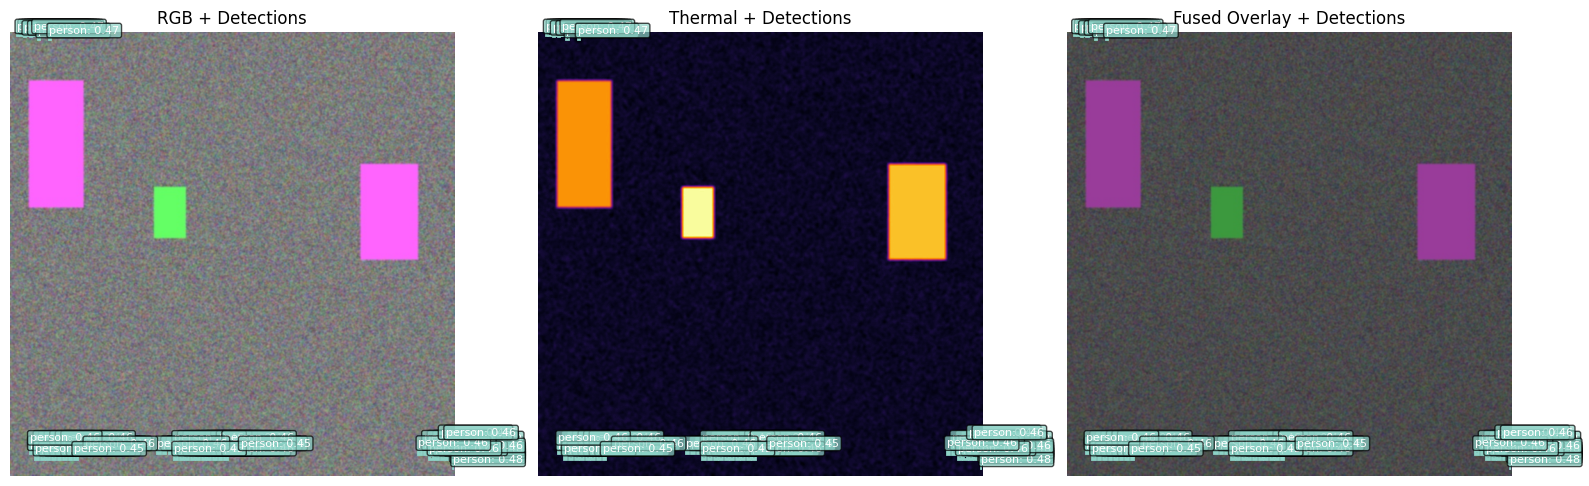


img_0001.jpg: 100 detections
  person: 0.616 at [22, 1, 24, 4]
  person: 0.612 at [18, 1, 20, 4]
  person: 0.609 at [26, 1, 28, 4]
  person: 0.597 at [14, 1, 16, 4]
  person: 0.589 at [28, 3, 30, 6]
  person: 0.587 at [20, 3, 22, 6]
  person: 0.586 at [30, 1, 32, 4]
  person: 0.565 at [10, 1, 12, 4]
  person: 0.552 at [36, 3, 38, 6]
  person: 0.549 at [34, 1, 36, 4]
  person: 0.538 at [636, 603, 638, 606]
  person: 0.535 at [40, 7, 42, 10]
  person: 0.533 at [636, 611, 639, 614]
  person: 0.530 at [12, 3, 14, 6]
  person: 0.518 at [60, 601, 64, 607]
  person: 0.518 at [56, 7, 58, 10]
  person: 0.518 at [68, 601, 72, 607]
  person: 0.517 at [636, 595, 638, 597]
  person: 0.516 at [52, 601, 56, 607]
  person: 0.515 at [76, 601, 80, 607]
  person: 0.514 at [628, 602, 632, 607]
  person: 0.512 at [22, 4, 26, 9]
  person: 0.511 at [84, 601, 88, 607]
  person: 0.510 at [44, 601, 48, 607]
  person: 0.510 at [26, 4, 29, 9]
  person: 0.509 at [28, 10, 31, 15]
  person: 0.505 at [638, 617, 640,

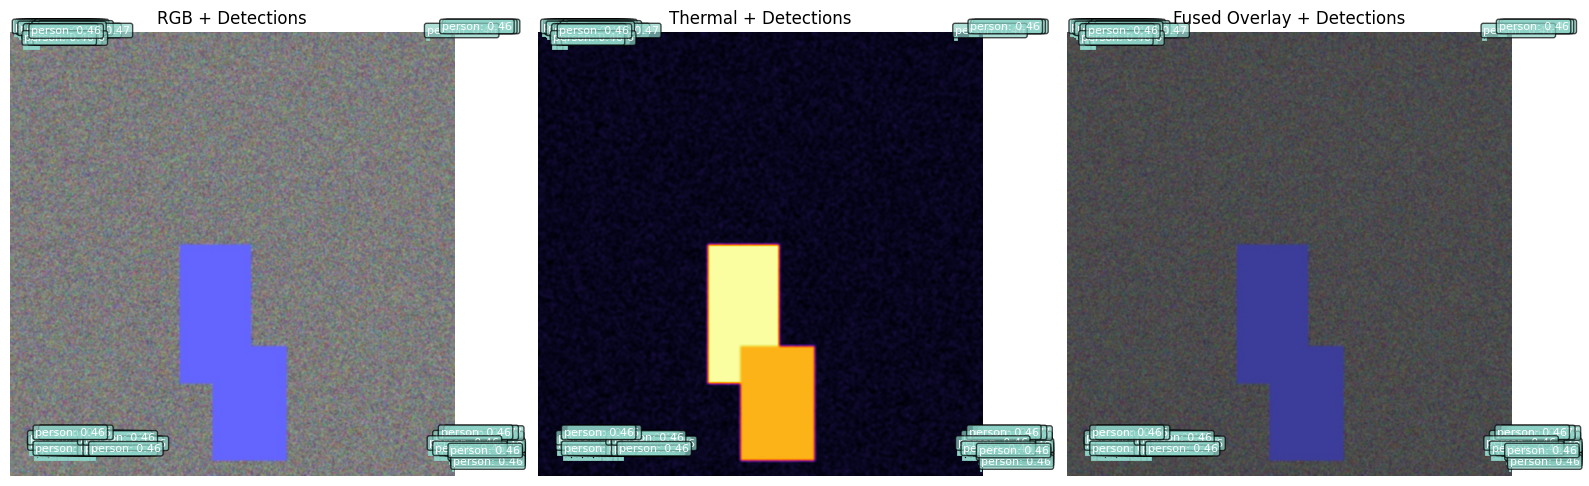

In [3]:
# Run detection on sample images
rgb_dir = os.path.join(DATA_DIR, 'rgb')
thermal_dir = os.path.join(DATA_DIR, 'thermal')

for i in range(min(2, len(os.listdir(rgb_dir)))):
    fname = f'img_{i:04d}.jpg'
    rgb_path = os.path.join(rgb_dir, fname)
    thermal_path = os.path.join(thermal_dir, fname)
    
    if not os.path.exists(rgb_path):
        continue
    
    detections, rgb_img, thermal_img = inferencer.detect_from_paths(rgb_path, thermal_path)
    
    print(f'\n{fname}: {len(detections)} detections')
    for det in detections:
        print(f'  {det["class_name"]}: {det["score"]:.3f} at '
              f'[{det["bbox"][0]:.0f}, {det["bbox"][1]:.0f}, '
              f'{det["bbox"][2]:.0f}, {det["bbox"][3]:.0f}]')
    
    fig = visualize_detections(
        rgb_img, thermal_img, detections,
        class_names=inferencer.class_names
    )
    plt.show()

## Feature Map Visualization

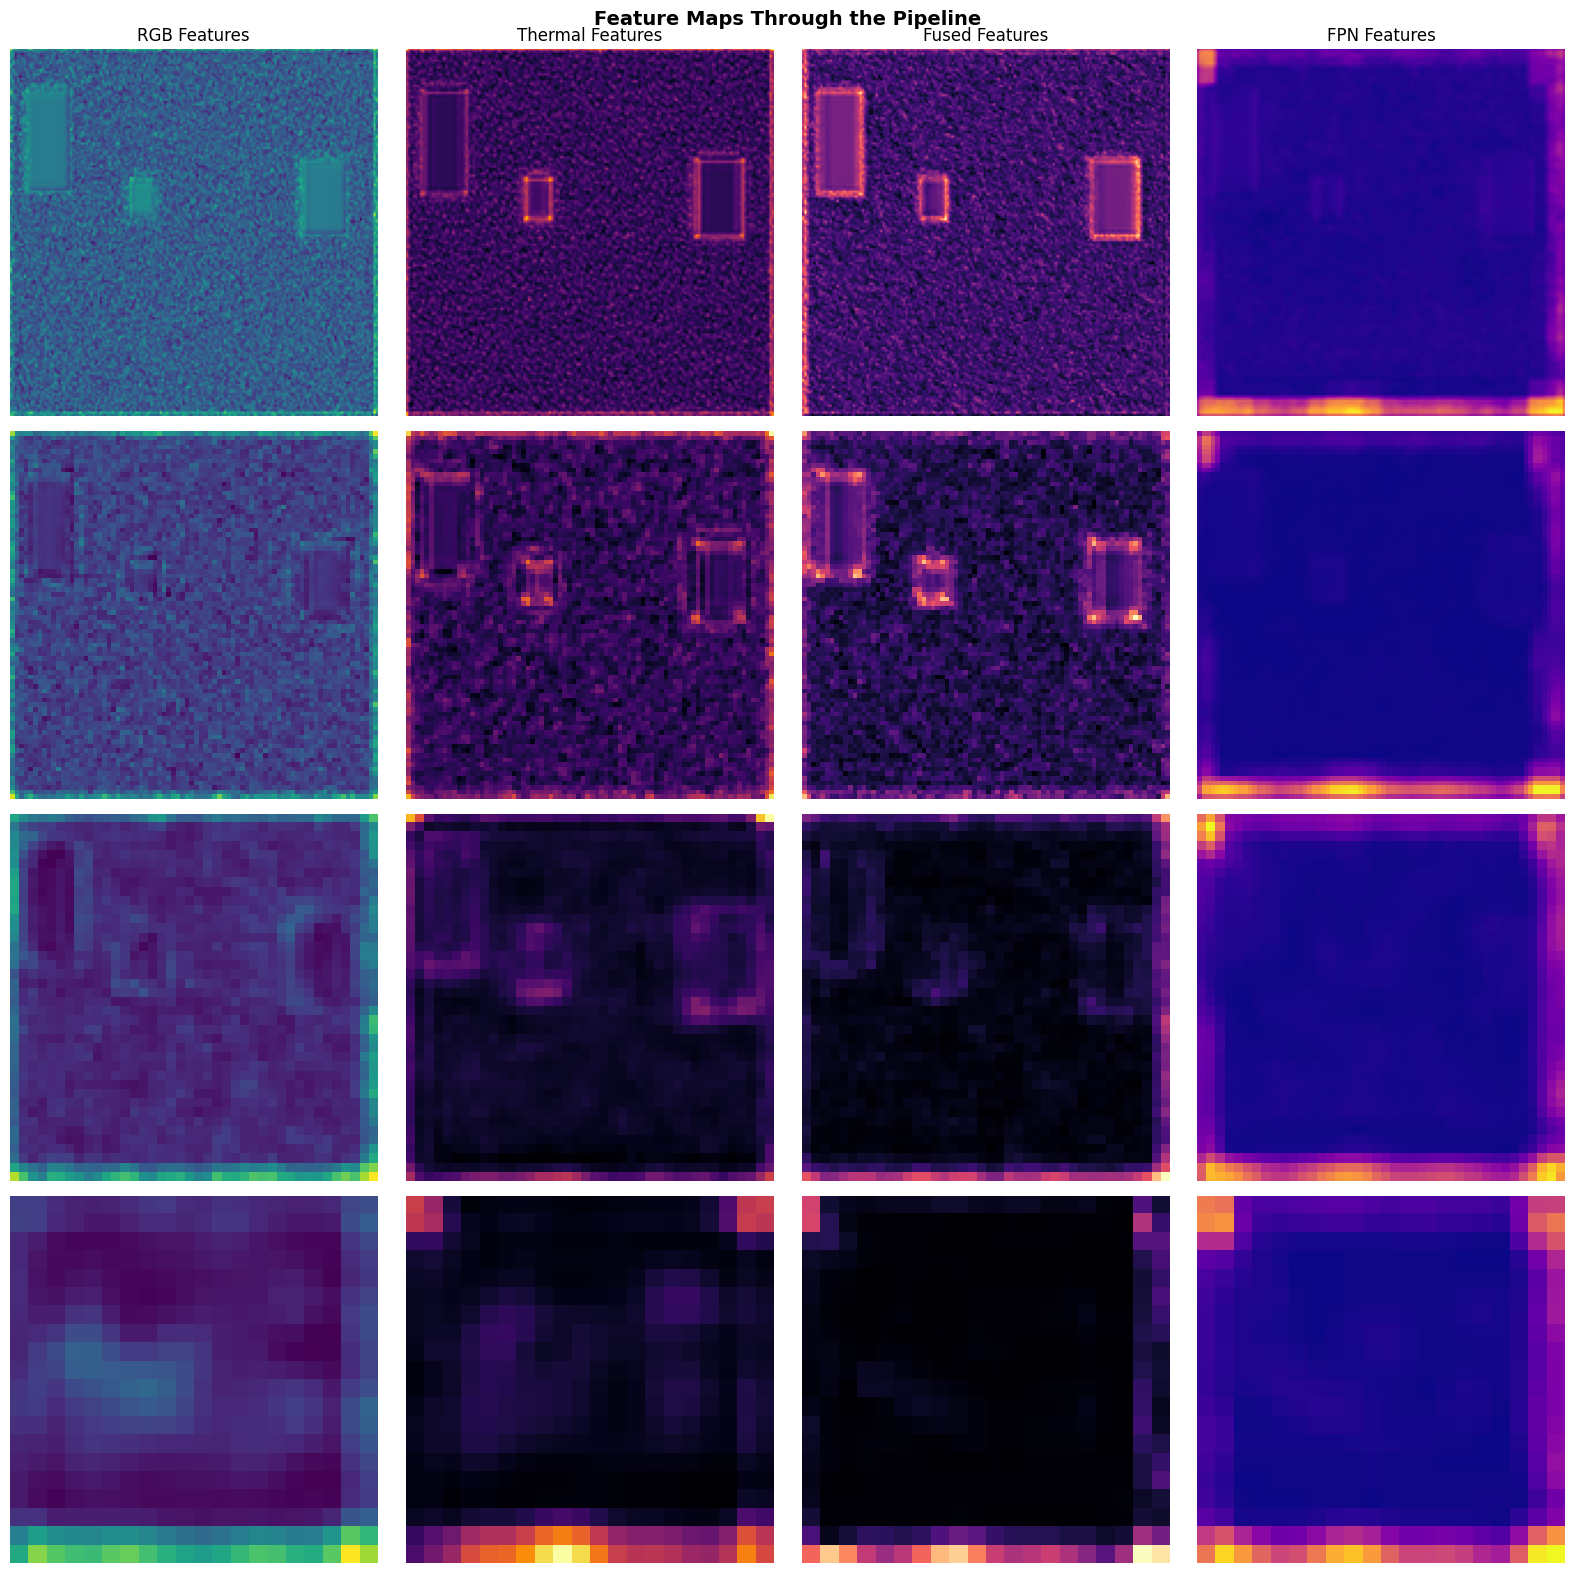

In [4]:
# Visualize intermediate feature maps
rgb_img = load_image(os.path.join(rgb_dir, 'img_0000.jpg'), 'rgb')
thermal_img = load_image(os.path.join(thermal_dir, 'img_0000.jpg'), 'thermal')

feat_maps = inferencer.get_feature_maps(rgb_img, thermal_img)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
titles = ['RGB Features', 'Thermal Features', 'Fused Features', 'FPN Features']
keys = ['rgb_features', 'thermal_features', 'fused_features', 'fpn_features']
cmaps = ['viridis', 'inferno', 'magma', 'plasma']

for col, (key, title, cmap) in enumerate(zip(keys, titles, cmaps)):
    for row in range(4):
        feat = feat_maps[key][row][0].mean(dim=0).cpu().numpy()
        axes[row, col].imshow(feat, cmap=cmap)
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(title, fontsize=12)
        if col == 0:
            axes[row, col].set_ylabel(f'Level {row+1}', fontsize=11)

plt.suptitle('Feature Maps Through the Pipeline', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()